In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

PROJECT_ROOT = Path.cwd().parent

# Load modelling dataset
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "customer_modeling_dataset.csv"
)

df = pd.read_csv(DATA_PATH)

# Load trained HGB model
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "hist_gradient_boosting_model.joblib"
)

PREPROCESSOR_PATH = (
    PROJECT_ROOT
    / "models"
    / "hgb_preprocessor.joblib"
)

hgb_model = joblib.load(MODEL_PATH)
preprocessor = joblib.load(PREPROCESSOR_PATH)

print("Dataset:", df.shape)
print("Model loaded successfully.")
print("Preprocessor loaded successfully.")

Dataset: (2600, 35)
Model loaded successfully.
Preprocessor loaded successfully.


In [6]:
TARGET = "CHURNED"

DROP_COLUMNS = [
    "CUSTOMER_ID",
    "CHURNED",
    "SIGNUP_DATE",
    "LAST_PURCHASE_MONTH"
]

X = df.drop(columns=DROP_COLUMNS)
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2600, 31)
y shape: (2600,)


In [7]:
test_mask = df["SIGNUP_YEAR"] == 2024

test_df = df.loc[test_mask].copy()
X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Test customers:", len(test_df))
print("\nTest target distribution:")
print(y_test.value_counts())

Test customers: 247

Test target distribution:
CHURNED
0    243
1      4
Name: count, dtype: int64


In [8]:
X_test_processed = preprocessor.transform(X_test)

test_prob_hgb = hgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("Number of predictions:", len(test_prob_hgb))
print("\nProbability summary:")
print(pd.Series(test_prob_hgb).describe())

Number of predictions: 247

Probability summary:
count    247.000000
mean       0.141333
std        0.143753
min        0.002547
25%        0.053911
50%        0.097750
75%        0.170114
max        0.930444
dtype: float64


In [9]:
retention_df = test_df[
    [
        "CUSTOMER_ID",
        "CHURNED",
        "MEMBERSHIP_TIER",
        "CITY"
    ]
].copy()

retention_df["CHURN_PROBABILITY"] = test_prob_hgb

retention_df["HIGH_RISK"] = (
    retention_df["CHURN_PROBABILITY"] >= 0.50
).astype(int)

print(retention_df.head())
print("\nHigh-risk customers:", retention_df["HIGH_RISK"].sum())

    CUSTOMER_ID  CHURNED MEMBERSHIP_TIER      CITY  CHURN_PROBABILITY  \
10       500011        0          Silver    Austin           0.137899   
13       500014        1            Gold    Austin           0.811862   
25       500026        0            Gold  Portland           0.070794   
52       500053        0            Gold    Austin           0.158244   
55       500056        0            Gold   Spokane           0.025242   

    HIGH_RISK  
10          0  
13          1  
25          0  
52          0  
55          0  

High-risk customers: 8


In [10]:
# ============================================================
# RETENTION SCENARIO ASSUMPTIONS
# ============================================================

INTERVENTION_COST = 10.0       # cost per targeted customer
RETENTION_SUCCESS_RATE = 0.20  # assumed 20% intervention success
CUSTOMER_VALUE = 100.0         # assumed value preserved per retained customer

print("Intervention cost:", INTERVENTION_COST)
print("Retention success rate:", RETENTION_SUCCESS_RATE)
print("Customer value:", CUSTOMER_VALUE)

Intervention cost: 10.0
Retention success rate: 0.2
Customer value: 100.0


In [11]:
# ============================================================
# SCENARIO A — TARGET CUSTOMERS WITH CHURN PROBABILITY >= 0.50
# ============================================================

high_risk_customers = retention_df["HIGH_RISK"].sum()

estimated_retained = (
    high_risk_customers * RETENTION_SUCCESS_RATE
)

intervention_cost = (
    high_risk_customers * INTERVENTION_COST
)

estimated_value_saved = (
    estimated_retained * CUSTOMER_VALUE
)

net_impact = (
    estimated_value_saved - intervention_cost
)

print("=== RETENTION SCENARIO — THRESHOLD 0.50 ===")

print("High-risk customers :", high_risk_customers)
print("Estimated retained  :", estimated_retained)
print("Intervention cost   :", intervention_cost)
print("Estimated value saved:", estimated_value_saved)
print("Estimated net impact:", net_impact)

=== RETENTION SCENARIO — THRESHOLD 0.50 ===
High-risk customers : 8
Estimated retained  : 1.6
Intervention cost   : 80.0
Estimated value saved: 160.0
Estimated net impact: 80.0


In [12]:
# ============================================================
# COMPARE RETENTION TARGETING STRATEGIES
# ============================================================

def calculate_scenario(target_count):
    
    estimated_retained = (
        target_count * RETENTION_SUCCESS_RATE
    )
    
    intervention_cost = (
        target_count * INTERVENTION_COST
    )
    
    estimated_value_saved = (
        estimated_retained * CUSTOMER_VALUE
    )
    
    net_impact = (
        estimated_value_saved - intervention_cost
    )
    
    return {
        "Targeted Customers": target_count,
        "Estimated Retained": estimated_retained,
        "Intervention Cost": intervention_cost,
        "Estimated Value Saved": estimated_value_saved,
        "Estimated Net Impact": net_impact
    }


# Scenario A: probability >= 0.50
threshold_count = (
    retention_df["CHURN_PROBABILITY"] >= 0.50
).sum()


# Scenario B: top 10%
top_10_count = max(
    1,
    int(np.ceil(len(retention_df) * 0.10))
)


# Scenario C: top 20%
top_20_count = max(
    1,
    int(np.ceil(len(retention_df) * 0.20))
)


scenario_results = pd.DataFrame([
    {
        "Strategy": "Probability >= 0.50",
        **calculate_scenario(threshold_count)
    },
    {
        "Strategy": "Top 10% Risk",
        **calculate_scenario(top_10_count)
    },
    {
        "Strategy": "Top 20% Risk",
        **calculate_scenario(top_20_count)
    }
])

scenario_results

,Strategy,Targeted Customers,Estimated Retained,Intervention Cost,Estimated Value Saved,Estimated Net Impact
0,Probability >= 0.50,8,1.6,80.0,160.0,80.0
1,Top 10% Risk,25,5.0,250.0,500.0,250.0
2,Top 20% Risk,50,10.0,500.0,1000.0,500.0


In [13]:
OUTPUT_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "retention_scenario_results.csv"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

scenario_results.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Retention scenario saved to:")
print(OUTPUT_PATH)

Retention scenario saved to:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\tables\retention_scenario_results.csv


# Create final churn predictions

In [14]:
# ============================================================
# FINAL CUSTOMER-LEVEL CHURN PREDICTIONS
# ============================================================

# Transform all customers using the saved preprocessing pipeline
X_all_processed = preprocessor.transform(X)

# Generate churn probabilities
all_probabilities = hgb_model.predict_proba(
    X_all_processed
)[:, 1]

# Use the validation-selected threshold
SELECTED_THRESHOLD = 0.91

all_predictions = (
    all_probabilities >= SELECTED_THRESHOLD
).astype(int)

print("Customers scored:", len(all_probabilities))
print("Predicted churners:", all_predictions.sum())
print("Predicted retained:", (all_predictions == 0).sum())

Customers scored: 2600
Predicted churners: 785
Predicted retained: 1815


In [15]:
# ============================================================
# BUILD FINAL PREDICTION DATAFRAME
# ============================================================

final_predictions = df[
    [
        "CUSTOMER_ID",
        "CHURNED",
        "MEMBERSHIP_TIER",
        "CITY",
        "SIGNUP_YEAR"
    ]
].copy()

final_predictions["CHURN_PROBABILITY"] = all_probabilities

final_predictions["PREDICTED_CHURN"] = all_predictions

# Sort highest-risk customers first
final_predictions = final_predictions.sort_values(
    "CHURN_PROBABILITY",
    ascending=False
).reset_index(drop=True)

print(final_predictions.head(10))

   CUSTOMER_ID  CHURNED MEMBERSHIP_TIER       CITY  SIGNUP_YEAR  \
0       502215        1            Gold     Austin         2021   
1       500603        1          Silver  Nashville         2023   
2       501663        1            Gold      Boise         2022   
3       501556        1          Silver    Spokane         2022   
4       501515        1          Silver   Columbus         2021   
5       501091        1          Silver  Nashville         2021   
6       501531        1          Silver   Columbus         2022   
7       501046        1          Silver    Madison         2022   
8       501286        1          Silver  Nashville         2023   
9       502185        1          Silver    Spokane         2022   

   CHURN_PROBABILITY  PREDICTED_CHURN  
0           0.999953                1  
1           0.999949                1  
2           0.999943                1  
3           0.999943                1  
4           0.999940                1  
5           0.999940  

In [16]:
# ============================================================
# SAVE FINAL CUSTOMER PREDICTIONS
# ============================================================

PREDICTION_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "predictions"
    / "churn_predictions.csv"
)

PREDICTION_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

final_predictions.to_csv(
    PREDICTION_PATH,
    index=False
)

print("\nFinal prediction file saved:")
print(PREDICTION_PATH)


Final prediction file saved:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\predictions\churn_predictions.csv


#  shap value for all 2600

In [17]:
# ============================================================
# CUSTOMER-LEVEL SHAP EXPLANATIONS
# ============================================================

import shap

# Create SHAP explainer for the trained HGB model
explainer = shap.TreeExplainer(hgb_model)

# Calculate SHAP values for all customers
shap_values_all = explainer.shap_values(
    X_all_processed
)

print("SHAP shape:", shap_values_all.shape)

SHAP shape: (2600, 94)


In [18]:
# ============================================================
# GET TRANSFORMED FEATURE NAMES
# ============================================================

feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("\nFirst 20 features:")
print(feature_names[:20])

Number of feature names: 94

First 20 features:
['num__AGE' 'num__MARKETING_OPT_IN' 'num__total_transactions'
 'num__total_spend' 'num__avg_basket_value' 'num__active_months'
 'num__observed_months' 'num__RECENCY_MONTHS'
 'num__NO_HISTORICAL_PURCHASE' 'num__avg_app_sessions'
 'num__total_app_sessions' 'num__avg_emails_opened'
 'num__total_emails_opened' 'num__total_coupons_redeemed'
 'num__avg_distinct_categories' 'num__avg_promo_txn_pct'
 'num__total_support_tickets' 'num__avg_support_tickets'
 'num__complaint_count' 'num__complaint_rate']


In [19]:
# ============================================================
# TOP 3 SHAP DRIVERS PER CUSTOMER
# ============================================================

def get_top_drivers(shap_row, feature_names, n=3):
    
    # Sort by absolute SHAP magnitude
    top_indices = np.argsort(
        np.abs(shap_row)
    )[::-1][:n]
    
    drivers = [
        feature_names[i]
        for i in top_indices
    ]
    
    return drivers


top_drivers = [
    get_top_drivers(
        shap_values_all[i],
        feature_names,
        n=3
    )
    for i in range(len(df))
]

final_predictions["KEY_DRIVER_1"] = [
    x[0] for x in top_drivers
]

final_predictions["KEY_DRIVER_2"] = [
    x[1] for x in top_drivers
]

final_predictions["KEY_DRIVER_3"] = [
    x[2] for x in top_drivers
]

print(
    final_predictions[
        [
            "CUSTOMER_ID",
            "CHURN_PROBABILITY",
            "PREDICTED_CHURN",
            "KEY_DRIVER_1",
            "KEY_DRIVER_2",
            "KEY_DRIVER_3"
        ]
    ].head(10)
)

   CUSTOMER_ID  CHURN_PROBABILITY  PREDICTED_CHURN             KEY_DRIVER_1  \
0       502215           0.999953                1      num__RECENCY_MONTHS   
1       500603           0.999949                1      num__RECENCY_MONTHS   
2       501663           0.999943                1      num__RECENCY_MONTHS   
3       501556           0.999943                1      num__RECENCY_MONTHS   
4       501515           0.999940                1  num__total_transactions   
5       501091           0.999940                1  num__total_app_sessions   
6       501531           0.999940                1      num__RECENCY_MONTHS   
7       501046           0.999939                1      num__RECENCY_MONTHS   
8       501286           0.999937                1      num__RECENCY_MONTHS   
9       502185           0.999937                1      num__RECENCY_MONTHS   

                  KEY_DRIVER_2                          KEY_DRIVER_3  
0         num__observed_months  cat__PREFERRED_CATEGORY_Fro

In [20]:
# ============================================================
# CLEAN SHAP FEATURE NAMES
# ============================================================

def clean_driver_name(name):
    
    name = name.replace("num__", "")
    name = name.replace("cat__", "")
    
    return name


for col in [
    "KEY_DRIVER_1",
    "KEY_DRIVER_2",
    "KEY_DRIVER_3"
]:
    
    final_predictions[col] = (
        final_predictions[col]
        .apply(clean_driver_name)
    )

print(
    final_predictions[
        [
            "CUSTOMER_ID",
            "CHURN_PROBABILITY",
            "PREDICTED_CHURN",
            "KEY_DRIVER_1",
            "KEY_DRIVER_2",
            "KEY_DRIVER_3"
        ]
    ].head(10)
)

   CUSTOMER_ID  CHURN_PROBABILITY  PREDICTED_CHURN        KEY_DRIVER_1  \
0       502215           0.999953                1      RECENCY_MONTHS   
1       500603           0.999949                1      RECENCY_MONTHS   
2       501663           0.999943                1      RECENCY_MONTHS   
3       501556           0.999943                1      RECENCY_MONTHS   
4       501515           0.999940                1  total_transactions   
5       501091           0.999940                1  total_app_sessions   
6       501531           0.999940                1      RECENCY_MONTHS   
7       501046           0.999939                1      RECENCY_MONTHS   
8       501286           0.999937                1      RECENCY_MONTHS   
9       502185           0.999937                1      RECENCY_MONTHS   

             KEY_DRIVER_2                     KEY_DRIVER_3  
0         observed_months  PREFERRED_CATEGORY_Frozen Foods  
1       avg_emails_opened           CUSTOMER_TENURE_MONTHS  
2 

In [21]:
# ============================================================
# SAVE FINAL PREDICTION FILE WITH SHAP DRIVERS
# ============================================================

PREDICTION_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "predictions"
    / "churn_predictions.csv"
)

final_predictions.to_csv(
    PREDICTION_PATH,
    index=False
)

print("Final prediction file saved:")
print(PREDICTION_PATH)

print("\nShape:", final_predictions.shape)
print("\nColumns:")
print(final_predictions.columns.tolist())

Final prediction file saved:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\predictions\churn_predictions.csv

Shape: (2600, 10)

Columns:
['CUSTOMER_ID', 'CHURNED', 'MEMBERSHIP_TIER', 'CITY', 'SIGNUP_YEAR', 'CHURN_PROBABILITY', 'PREDICTED_CHURN', 'KEY_DRIVER_1', 'KEY_DRIVER_2', 'KEY_DRIVER_3']


In [22]:
# ============================================================
# SEGMENT RISK ANALYSIS — MEMBERSHIP TIER
# ============================================================

tier_risk = (
    final_predictions
    .groupby("MEMBERSHIP_TIER")
    .agg(
        CUSTOMERS=("CUSTOMER_ID", "count"),
        AVG_PREDICTED_RISK=("CHURN_PROBABILITY", "mean"),
        OBSERVED_CHURN_RATE=("CHURNED", "mean"),
        PREDICTED_CHURN_COUNT=("PREDICTED_CHURN", "sum")
    )
    .reset_index()
)

tier_risk["OBSERVED_CHURN_RATE"] *= 100
tier_risk["AVG_PREDICTED_RISK"] *= 100

tier_risk = tier_risk.sort_values(
    "AVG_PREDICTED_RISK",
    ascending=False
)

tier_risk

,MEMBERSHIP_TIER,CUSTOMERS,AVG_PREDICTED_RISK,OBSERVED_CHURN_RATE,PREDICTED_CHURN_COUNT
2,Silver,1474,37.569826,32.293080,455
0,Gold,824,33.301900,30.097087,245
1,Platinum,302,32.250338,31.125828,85


In [23]:
# ============================================================
# SEGMENT RISK ANALYSIS — CITY
# ============================================================

city_risk = (
    final_predictions
    .groupby("CITY")
    .agg(
        CUSTOMERS=("CUSTOMER_ID", "count"),
        AVG_PREDICTED_RISK=("CHURN_PROBABILITY", "mean"),
        OBSERVED_CHURN_RATE=("CHURNED", "mean"),
        PREDICTED_CHURN_COUNT=("PREDICTED_CHURN", "sum")
    )
    .reset_index()
)

city_risk["OBSERVED_CHURN_RATE"] *= 100
city_risk["AVG_PREDICTED_RISK"] *= 100

city_risk = city_risk.sort_values(
    "AVG_PREDICTED_RISK",
    ascending=False
)

city_risk

,CITY,CUSTOMERS,AVG_PREDICTED_RISK,OBSERVED_CHURN_RATE,PREDICTED_CHURN_COUNT
2,Columbus,268,41.408021,36.194030,93
0,Austin,266,40.897948,37.593985,92
5,Nashville,237,37.687993,33.333333,78
1,Boise,247,37.150824,31.983806,77
3,Denver,257,33.864756,28.793774,74
4,Madison,256,33.833165,29.687500,73
9,Tulsa,295,33.559813,29.830508,84
7,Raleigh,282,33.317724,29.787234,86
6,Portland,240,32.784624,28.333333,62
8,Spokane,252,31.528547,28.968254,66


In [24]:
# ============================================================
# SEGMENT RISK ANALYSIS — SIGNUP COHORT
# ============================================================

cohort_risk = (
    final_predictions
    .groupby("SIGNUP_YEAR")
    .agg(
        CUSTOMERS=("CUSTOMER_ID", "count"),
        AVG_PREDICTED_RISK=("CHURN_PROBABILITY", "mean"),
        OBSERVED_CHURN_RATE=("CHURNED", "mean"),
        PREDICTED_CHURN_COUNT=("PREDICTED_CHURN", "sum")
    )
    .reset_index()
)

cohort_risk["OBSERVED_CHURN_RATE"] *= 100
cohort_risk["AVG_PREDICTED_RISK"] *= 100

cohort_risk

,SIGNUP_YEAR,CUSTOMERS,AVG_PREDICTED_RISK,OBSERVED_CHURN_RATE,PREDICTED_CHURN_COUNT
0,2021,745,37.475808,37.449664,274
1,2022,792,38.654303,38.636364,305
2,2023,816,37.418721,28.063725,205
3,2024,247,14.133315,1.619433,1


In [25]:
# ============================================================
# SAVE SEGMENT RISK TABLES
# ============================================================

TABLE_PATH = PROJECT_ROOT / "outputs" / "tables"
TABLE_PATH.mkdir(parents=True, exist_ok=True)

tier_risk.to_csv(
    TABLE_PATH / "segment_risk_by_tier.csv",
    index=False
)

city_risk.to_csv(
    TABLE_PATH / "segment_risk_by_city.csv",
    index=False
)

cohort_risk.to_csv(
    TABLE_PATH / "segment_risk_by_signup_cohort.csv",
    index=False
)

print("Segment risk tables saved successfully.")

Segment risk tables saved successfully.


In [26]:
# ============================================================
# SAVE SEGMENT ANALYSIS TO EXCEL
# ============================================================

SEGMENT_EXCEL_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "segment_risk_analysis.xlsx"
)

with pd.ExcelWriter(SEGMENT_EXCEL_PATH, engine="openpyxl") as writer:
    tier_risk.to_excel(
        writer,
        sheet_name="By_Tier",
        index=False
    )
    
    city_risk.to_excel(
        writer,
        sheet_name="By_City",
        index=False
    )
    
    cohort_risk.to_excel(
        writer,
        sheet_name="By_Signup_Cohort",
        index=False
    )

print("Segment analysis Excel saved:")
print(SEGMENT_EXCEL_PATH)

Segment analysis Excel saved:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\tables\segment_risk_analysis.xlsx


In [27]:
# ============================================================
# FINAL MODEL COMPARISON TABLE
# ============================================================

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.4069,
        "Precision": 0.3207,
        "Recall": 0.9956,
        "F1": 0.4851,
        "PR_AUC": 0.4188
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.5490,
        "Precision": 0.3828,
        "Recall": 0.9913,
        "F1": 0.5523,
        "PR_AUC": 0.9348
    },
    {
        "Model": "HistGradientBoosting",
        "Accuracy": 0.8897,
        "Precision": 0.7509,
        "Recall": 0.9083,
        "F1": 0.8221,
        "PR_AUC": 0.9382
    }
])

model_comparison

,Model,Accuracy,Precision,Recall,F1,PR_AUC
0,Logistic Regression,0.4069,0.3207,0.9956,0.4851,0.4188
1,Random Forest,0.5490,0.3828,0.9913,0.5523,0.9348
2,HistGradientBoosting,0.8897,0.7509,0.9083,0.8221,0.9382


In [28]:
MODEL_TABLE_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "model_comparison.csv"
)

model_comparison.to_csv(
    MODEL_TABLE_PATH,
    index=False
)

print("Model comparison saved:")
print(MODEL_TABLE_PATH)

Model comparison saved:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\tables\model_comparison.csv


In [29]:
# ============================================================
# FINAL HOLDOUT TEST RESULTS
# ============================================================

test_results = pd.DataFrame([
    {
        "Threshold": 0.50,
        "Accuracy": 0.9838,
        "Precision": 0.5000,
        "Recall": 1.0000,
        "F1": 0.6667,
        "PR_AUC": 0.7679
    },
    {
        "Threshold": 0.91,
        "Accuracy": 0.9879,
        "Precision": 1.0000,
        "Recall": 0.2500,
        "F1": 0.4000,
        "PR_AUC": 0.7679
    }
])

test_results

,Threshold,Accuracy,Precision,Recall,F1,PR_AUC
0,0.50,0.9838,0.5,1.00,0.6667,0.7679
1,0.91,0.9879,1.0,0.25,0.4000,0.7679


In [30]:
TEST_RESULTS_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "2024_test_threshold_results.csv"
)

test_results.to_csv(
    TEST_RESULTS_PATH,
    index=False
)

print("2024 test results saved:")
print(TEST_RESULTS_PATH)

2024 test results saved:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\tables\2024_test_threshold_results.csv


## FINAL VISUALS

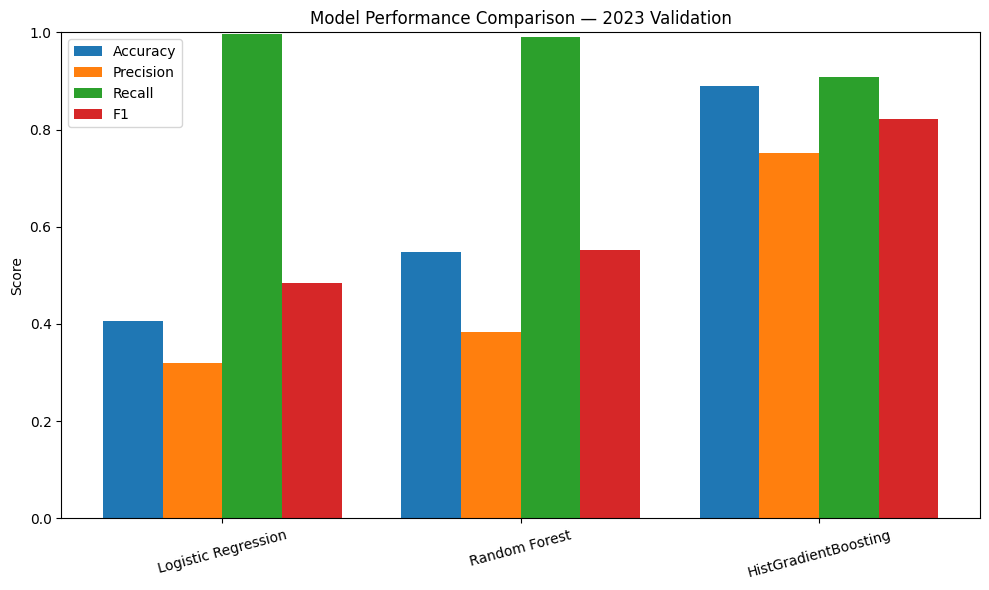

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\figures\model_comparison.png


In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

x = np.arange(len(model_comparison))
width = 0.2

plt.bar(
    x - 1.5 * width,
    model_comparison["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x - 0.5 * width,
    model_comparison["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x + 0.5 * width,
    model_comparison["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + 1.5 * width,
    model_comparison["F1"],
    width,
    label="F1"
)

plt.xticks(
    x,
    model_comparison["Model"],
    rotation=15
)

plt.ylabel("Score")
plt.title("Model Performance Comparison — 2023 Validation")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

FIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "model_comparison.png"
)

FIG_PATH.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIG_PATH)

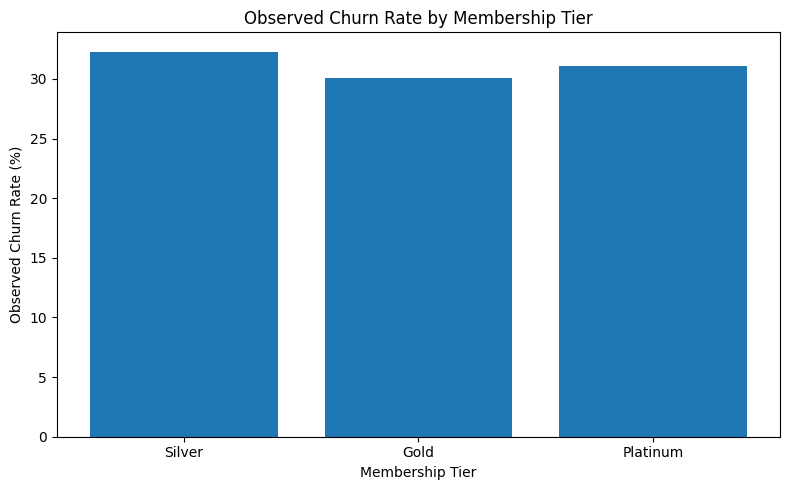

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\figures\churn_by_membership_tier.png


In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    tier_risk["MEMBERSHIP_TIER"],
    tier_risk["OBSERVED_CHURN_RATE"]
)

plt.ylabel("Observed Churn Rate (%)")
plt.xlabel("Membership Tier")
plt.title("Observed Churn Rate by Membership Tier")

plt.tight_layout()

FIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "churn_by_membership_tier.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIG_PATH)

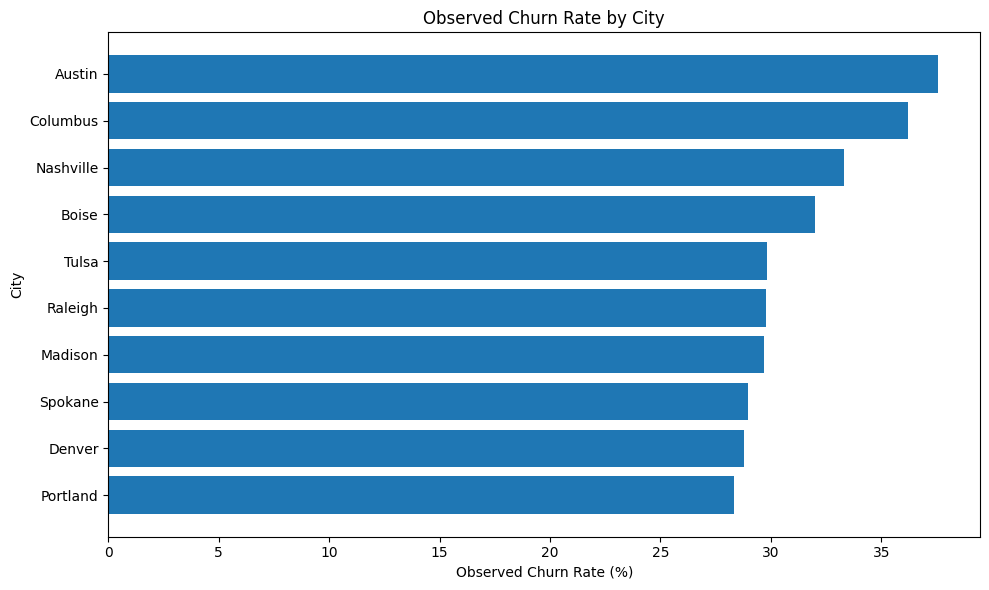

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\figures\churn_by_city.png


In [33]:
plt.figure(figsize=(10, 6))

city_plot = city_risk.sort_values(
    "OBSERVED_CHURN_RATE"
)

plt.barh(
    city_plot["CITY"],
    city_plot["OBSERVED_CHURN_RATE"]
)

plt.xlabel("Observed Churn Rate (%)")
plt.ylabel("City")
plt.title("Observed Churn Rate by City")

plt.tight_layout()

FIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "churn_by_city.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIG_PATH)

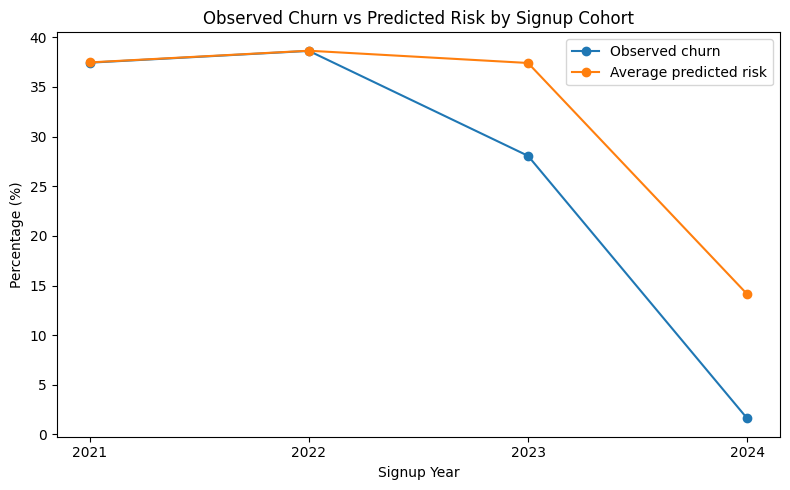

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\figures\cohort_observed_vs_predicted.png


In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    cohort_risk["SIGNUP_YEAR"].astype(str),
    cohort_risk["OBSERVED_CHURN_RATE"],
    marker="o",
    label="Observed churn"
)

plt.plot(
    cohort_risk["SIGNUP_YEAR"].astype(str),
    cohort_risk["AVG_PREDICTED_RISK"],
    marker="o",
    label="Average predicted risk"
)

plt.xlabel("Signup Year")
plt.ylabel("Percentage (%)")
plt.title("Observed Churn vs Predicted Risk by Signup Cohort")
plt.legend()

plt.tight_layout()

FIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "cohort_observed_vs_predicted.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIG_PATH)

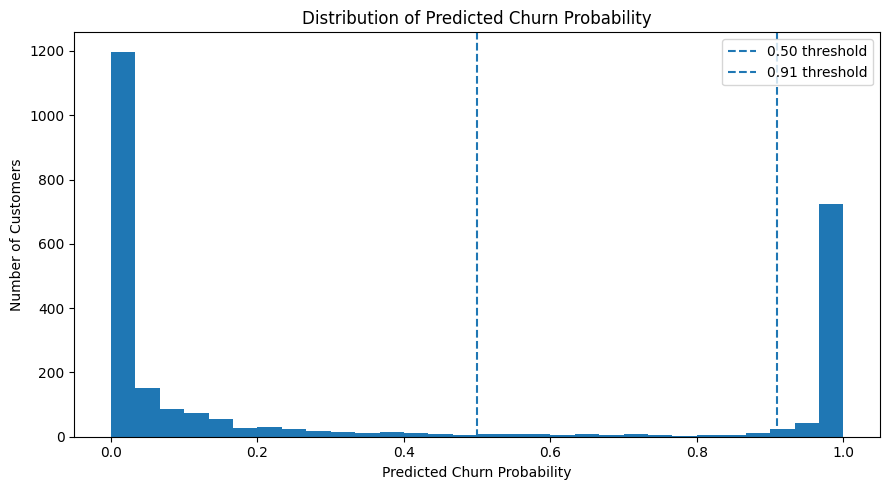

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\figures\churn_probability_distribution.png


In [35]:
plt.figure(figsize=(9, 5))

plt.hist(
    final_predictions["CHURN_PROBABILITY"],
    bins=30
)

plt.axvline(
    0.50,
    linestyle="--",
    label="0.50 threshold"
)

plt.axvline(
    0.91,
    linestyle="--",
    label="0.91 threshold"
)

plt.xlabel("Predicted Churn Probability")
plt.ylabel("Number of Customers")
plt.title("Distribution of Predicted Churn Probability")
plt.legend()

plt.tight_layout()

FIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "churn_probability_distribution.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIG_PATH)

In [38]:
shap_global = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "shap_global_feature_importance.csv"
)

print(shap_global.columns.tolist())
print(shap_global.head())

['Business_Driver', 'Model_Feature', 'Mean_Abs_SHAP']
         Business_Driver       Model_Feature  Mean_Abs_SHAP
0       Purchase recency      RECENCY_MONTHS       4.104578
1     Purchase frequency  total_transactions       0.845772
2  Historical engagement     observed_months       0.600471
3         App engagement  total_app_sessions       0.438006
4       Email engagement   avg_emails_opened       0.390948


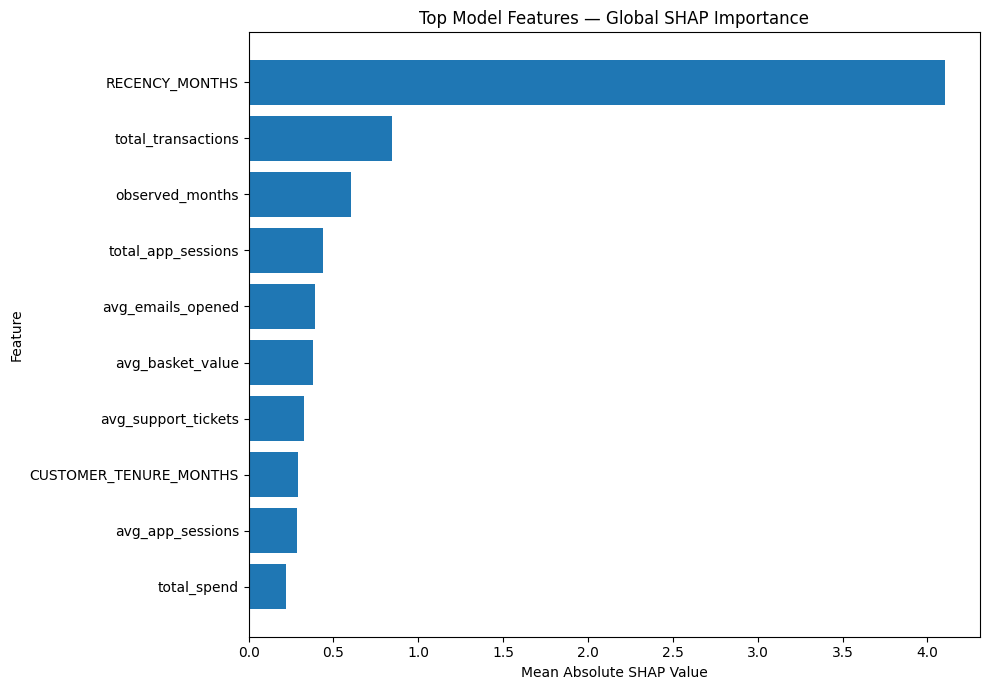

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\figures\shap_global_importance.png


: 

In [ ]:
# ============================================================
# SHAP GLOBAL IMPORTANCE VISUALIZATION
# ============================================================

shap_global = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "shap_global_feature_importance.csv"
)

# Select top 15 model features
shap_top = (
    shap_global
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=True
    )
    .tail(15)
)

plt.figure(figsize=(10, 7))

plt.barh(
    shap_top["Model_Feature"],
    shap_top["Mean_Abs_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top Model Features — Global SHAP Importance")

plt.tight_layout()

FIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "shap_global_importance.png"
)

FIG_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIG_PATH)